In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

import os
os.makedirs("images", exist_ok=True)

In [2]:
df = pd.read_csv("data/diabetes.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
print("Missing values (NaN) per column:")
print(df.isna().sum())
print("\nClass balance (Outcome):")
print(df["Outcome"].value_counts())
print((df["Outcome"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class balance (Outcome):
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.1 %
1    34.9 %
Name: proportion, dtype: str


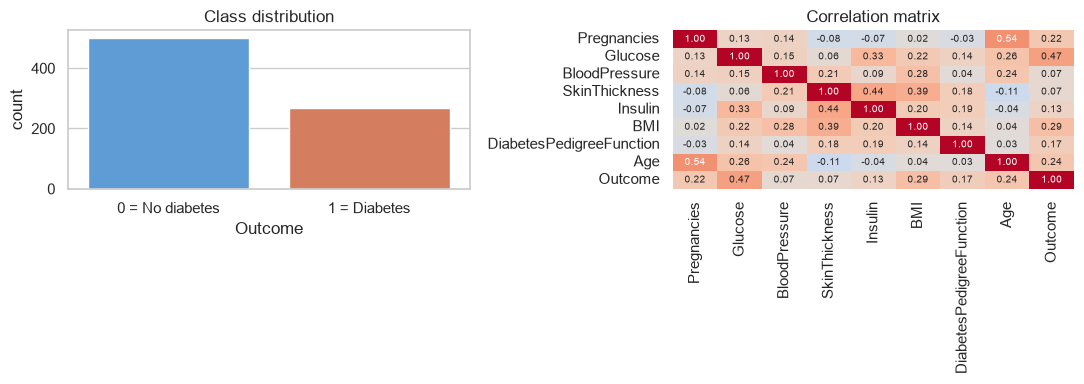

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="Outcome", ax=axes[0], palette=["#4C9BE8", "#E8744C"])
axes[0].set_title("Class distribution")
axes[0].set_xticklabels(["0 = No diabetes", "1 = Diabetes"])

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            ax=axes[1], cbar=False, annot_kws={"size": 7})
axes[1].set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("images/eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zeros before replacement:")
print((df[zero_as_missing] == 0).sum())

df_clean = df.copy()
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

print("\nNaN after replacement:")
print(df_clean[zero_as_missing].isna().sum())

Zeros before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

NaN after replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


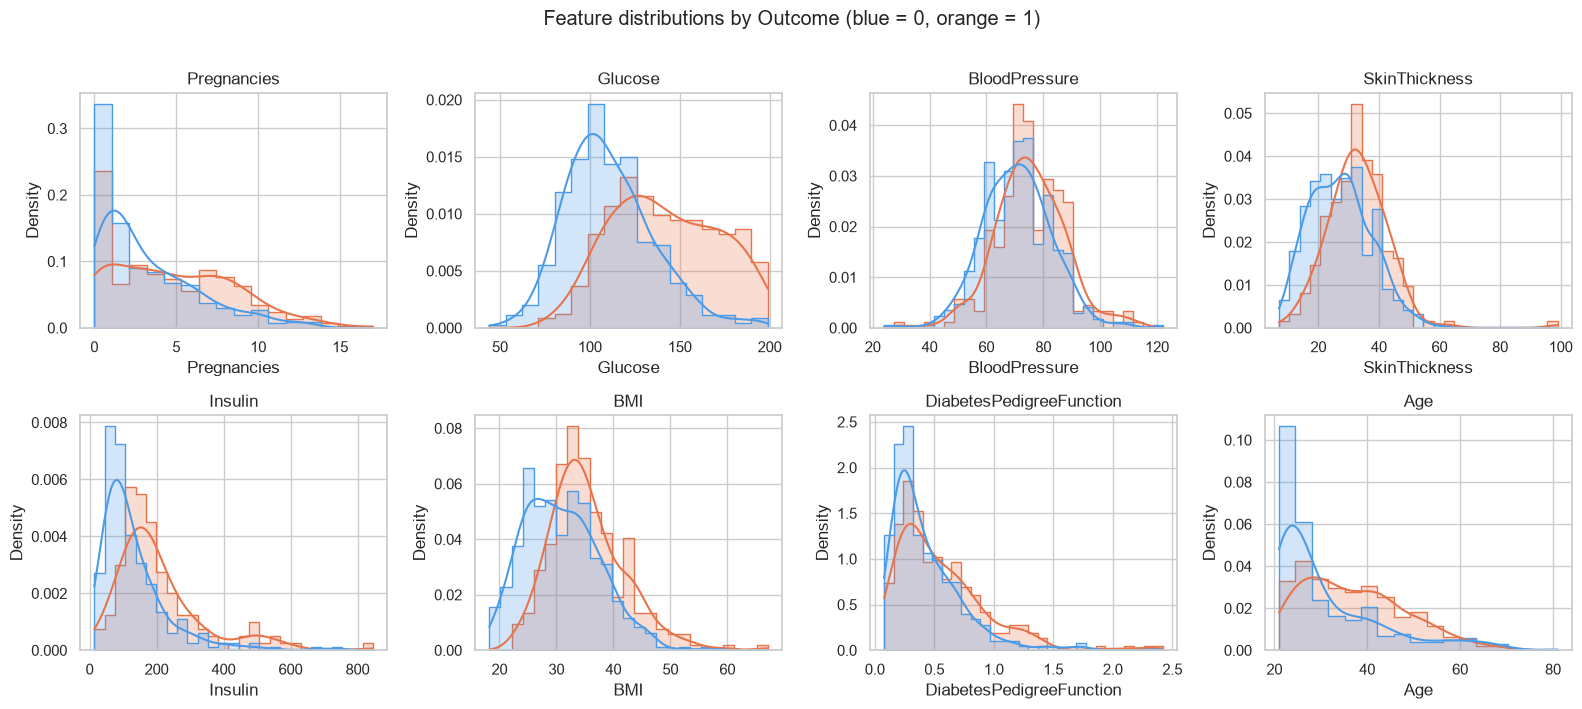

In [8]:
features = df_clean.drop(columns="Outcome").columns
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df_clean, x=col, hue="Outcome", kde=True, ax=ax,
                 palette=["#4C9BE8", "#E8744C"], element="step", stat="density",
                 common_norm=False)
    ax.set_title(col)
    ax.legend_.remove() if ax.get_legend() else None
fig.suptitle("Feature distributions by Outcome (blue = 0, orange = 1)", y=1.01)
plt.tight_layout()
plt.show()

In [9]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Positive rate - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (614, 8)  Test: (154, 8)
Positive rate - train: 0.349 | test: 0.351


In [10]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000,
                               random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For str

In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Result": [accuracy_score(y_test, y_pred),
               precision_score(y_test, y_pred),
               recall_score(y_test, y_pred),
               f1_score(y_test, y_pred),
               roc_auc_score(y_test, y_prob)],
    "Meaning": ["Overall correct predictions",
                "Reliability of positive predictions",
                "Actual positive cases detected",
                "Balance of precision and recall",
                "Overall class-separation ability"],
})
metrics["Result"] = metrics["Result"].round(3)
metrics

,Metric,Result,Meaning
0,Accuracy,0.734,Overall correct predictions
1,Precision,0.603,Reliability of positive predictions
2,Recall,0.704,Actual positive cases detected
3,F1-score,0.650,Balance of precision and recall
4,ROC-AUC,0.813,Overall class-separation ability


In [12]:
print(classification_report(y_test, y_pred, target_names=["No diabetes (0)", "Diabetes (1)"]))

                 precision    recall  f1-score   support

No diabetes (0)       0.82      0.75      0.79       100
   Diabetes (1)       0.60      0.70      0.65        54

       accuracy                           0.73       154
      macro avg       0.71      0.73      0.72       154
   weighted avg       0.75      0.73      0.74       154



,Predicted 0,Predicted 1
Actual 0,TN = 75,FP = 25
Actual 1,FN = 16,TP = 38


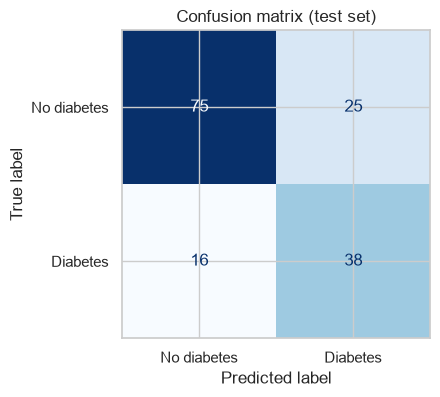

In [13]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

cm_table = pd.DataFrame(
    [[f"TN = {tn}", f"FP = {fp}"], [f"FN = {fn}", f"TP = {tp}"]],
    index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])
display(cm_table)

fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion matrix (test set)")
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

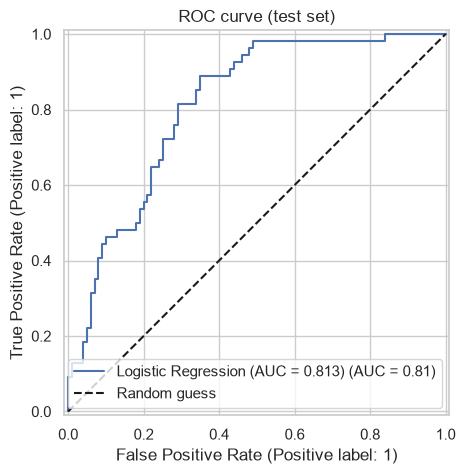

In [14]:

fig, ax = plt.subplots(figsize=(5.5, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax,
    name=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})"
)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")

plt.savefig("images/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()


In [15]:
coef = model.named_steps["clf"].coef_[0]
coef_df = (pd.DataFrame({"Feature": X.columns,
                         "Coefficient": coef,
                         "Odds ratio (per +1 SD)": np.exp(coef)})
             .sort_values("Coefficient", ascending=False)
             .reset_index(drop=True))
coef_df.round(3)

,Feature,Coefficient,Odds ratio (per +1 SD)
0,Glucose,1.183,3.266
1,BMI,0.710,2.033
2,Pregnancies,0.373,1.452
3,DiabetesPedigreeFunction,0.288,1.333
4,Age,0.186,1.205
5,SkinThickness,0.014,1.014
6,BloodPressure,-0.015,0.985
7,Insulin,-0.045,0.956


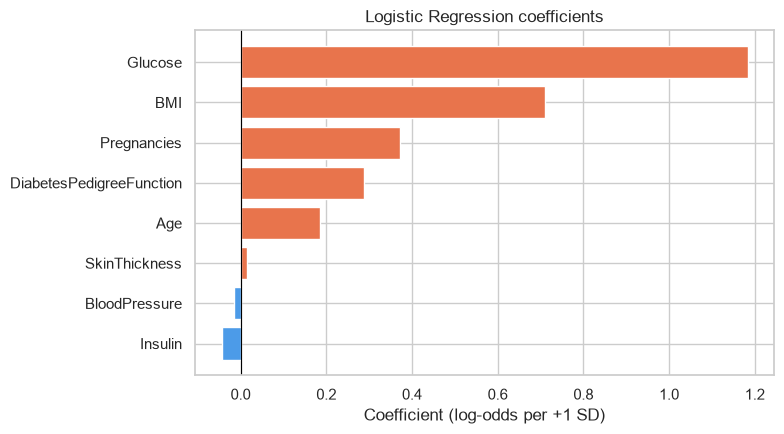

Strongest positive predictors: Glucose, BMI


In [16]:
plot_df = coef_df.sort_values("Coefficient")
colors = ["#E8744C" if c > 0 else "#4C9BE8" for c in plot_df["Coefficient"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (log-odds per +1 SD)")
ax.set_title("Logistic Regression coefficients")
plt.tight_layout()
plt.savefig("images/coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

print("Strongest positive predictors:", ", ".join(coef_df["Feature"].head(2)))

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(model, X, y, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

cv_df = pd.DataFrame({k.replace("test_", ""): v for k, v in scores.items()
                      if k.startswith("test_")})
summary = cv_df.agg(["mean", "std"]).T.round(3)
summary

,mean,std
accuracy,0.747,0.045
precision,0.623,0.070
recall,0.727,0.052
f1,0.669,0.045
roc_auc,0.836,0.022
